Original Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Normalized Data:
          0         1         2         3
0  0.222222  0.625000  0.067797  0.041667
1  0.166667  0.416667  0.067797  0.041667
2  0.111111  0.500000  0.050847  0.041667
3  0.083333  0.458333  0.084746  0.041667
4  0.194444  0.666667  0.067797  0.041667

Standardized Data:
          0         1         2         3
0 -0.900681  1.019004 -1.340227 -1.315444
1 -1.143017 -0.131979 -1.340227 -1.315444
2 -1.385353  0.328414 -1.397064 -1.315444
3 -1.506521  0.098217 -1.283389 -1.315444
4 -1.021849  1.249201 -1.3

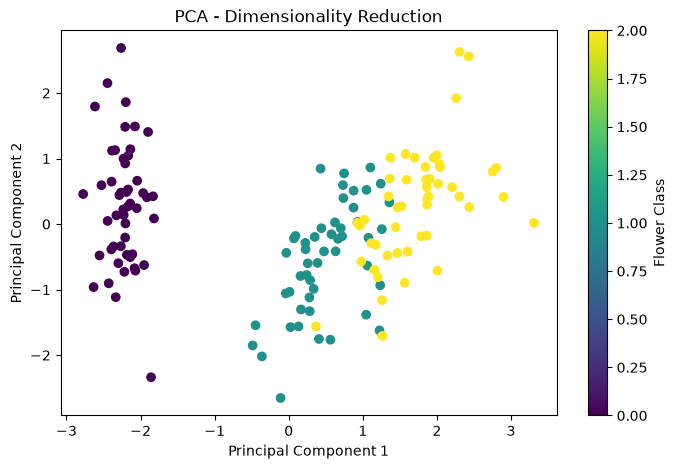

In [1]:

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

# Load dataset
iris = load_iris()
X = iris.data

df = pd.DataFrame(X, columns=iris.feature_names)

print("Original Dataset:")
print(df.head())

# 1. Normalization
normalizer = MinMaxScaler()
X_normalized = normalizer.fit_transform(X)

print("\nNormalized Data:")
print(pd.DataFrame(X_normalized).head())

# 2. Standardization
scaler = StandardScaler()
X_standardized = scaler.fit_transform(X)

print("\nStandardized Data:")
print(pd.DataFrame(X_standardized).head())

# 3. PCA - Dimensionality Reduction
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_standardized)

print("\nPCA Reduced Data:")
print(pd.DataFrame(X_pca, columns=['PC1', 'PC2']).head())

# Explained variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Variance Explained:",
      sum(pca.explained_variance_ratio_))

# PCA Visualization
plt.figure(figsize=(8, 5))

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=iris.target)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Dimensionality Reduction")
plt.colorbar(label="Flower Class")
plt.show()
